# Stellar Classification EDA
## Content
The data consists of 100,000 observations of space taken by the SDSS (Sloan Digital Sky Survey). Every observation is described by 17 feature columns and 1 class column which identifies it to be either a star, galaxy or quasar.

obj_ID = Object Identifier, the unique value that identifies the object in the image catalog used by the CAS
alpha = Right Ascension angle (at J2000 epoch)
delta = Declination angle (at J2000 epoch)
u = Ultraviolet filter in the photometric system
g = Green filter in the photometric system
r = Red filter in the photometric system
i = Near Infrared filter in the photometric system
z = Infrared filter in the photometric system
run_ID = Run Number used to identify the specific scan
rereun_ID = Rerun Number to specify how the image was processed
cam_col = Camera column to identify the scanline within the run
field_ID = Field number to identify each field
spec_obj_ID = Unique ID used for optical spectroscopic objects (this means that 2 different observations with the same spec_obj_ID must share the output class)
class = object class (galaxy, star or quasar object)
redshift = redshift value based on the increase in wavelength
plate = plate ID, identifies each plate in SDSS
MJD = Modified Julian Date, used to indicate when a given piece of SDSS data was taken
fiber_ID = fiber ID that identifies the fiber that pointed the light at the focal plane in each observation

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from matplotlib import style
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid", palette="magma")
style.use('ggplot')
np.random.seed(42)

## Load data

In [3]:
df = pd.read_csv('../dataset/star_classification.csv')
df.sample(5)

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
75721,1.237679e+18,16.956890,3.646130,23.33542,21.95143,20.48149,19.60300,19.13094,7712,301,6,442,4.855017e+18,GALAXY,0.506237,4312,55511,495
80184,1.237662e+18,240.063240,6.134131,17.86033,16.79228,16.43001,16.30923,16.25873,3894,301,1,243,2.448928e+18,STAR,0.000345,2175,54612,348
19864,1.237679e+18,30.887222,1.188710,18.18911,16.89469,16.42161,16.24627,16.18549,7717,301,1,536,8.255357e+18,STAR,0.000004,7332,56683,943
76699,1.237668e+18,247.594401,10.887780,24.99961,21.71203,21.47148,21.30532,21.29109,5323,301,1,134,4.577999e+18,STAR,-0.000291,4066,55444,326
92991,1.237679e+18,18.896451,-5.261330,23.76648,21.79737,20.69543,20.23403,19.97464,7881,301,3,148,8.910472e+18,STAR,-0.000136,7914,57331,363


In [4]:
df.shape

(100000, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

In [6]:
df.describe()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237665e+18,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,5.783882e+18,0.576661,5137.009660,55588.647500,449.312740
std,8.438560e+12,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,3.324016e+18,0.730707,2952.303351,1808.484233,272.498404
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,2.844138e+18,0.054517,2526.000000,54234.000000,221.000000
50%,1.237663e+18,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,5.614883e+18,0.424173,4987.000000,55868.500000,433.000000
75%,1.237668e+18,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,8.332144e+18,0.704154,7400.250000,56777.000000,645.000000
max,1.237681e+18,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


## Train test split

We chose a 90/10 split due to the large size of the dataset, consisting of 100,000 observations. This split allows for a substantial portion (90%) of the data to be used for training, ensuring that the model can learn effectively from a diverse range of examples. The remaining 10% is reserved for testing, providing an adequate evaluation of the model's performance on unseen data without sacrificing too much of the training set. This ratio strikes a balance between training efficiency and robust evaluation, facilitating reliable model development and assessment.

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['class'])
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

train = pd.concat([X_train, y_train], axis=1)
test = pd.concat([X_test, y_test], axis=1)

In [8]:
print("Proportion of classes in train and test sets:")
print(train['class'].value_counts(normalize=True))
print(test['class'].value_counts(normalize=True))

Proportion of classes in train and test sets:
class
GALAXY    0.594444
STAR      0.215944
QSO       0.189611
Name: proportion, dtype: float64
class
GALAXY    0.5945
STAR      0.2159
QSO       0.1896
Name: proportion, dtype: float64


In [9]:
df = train
df.shape

(90000, 18)

## Train set exploration

In [10]:
df.describe()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,9.000000e+04,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.0,90000.000000,90000.000000,9.000000e+04,90000.000000,90000.000000,90000.000000,90000.000000
mean,1.237665e+18,177.637544,24.150081,21.969317,20.521189,19.646641,19.085411,18.658354,4478.774556,301.0,3.511956,186.448444,5.786039e+18,0.576815,5138.925611,55589.748011,449.164800
std,8.436649e+12,96.427557,19.643325,33.479243,33.460865,1.854605,1.757448,33.439228,1964.319809,0.0,1.587163,149.367477,3.322714e+18,0.730581,2951.146441,1808.228122,272.623259
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.564837,5.165952,20.351843,18.966525,18.138717,17.734068,17.464363,3185.000000,301.0,2.000000,82.000000,2.845270e+18,0.054517,2527.000000,54234.000000,220.000000
50%,1.237663e+18,180.919818,23.687366,22.182025,21.098380,20.127485,19.406960,19.005195,4188.000000,301.0,4.000000,146.000000,5.616184e+18,0.423371,4988.000000,55869.000000,432.000000
75%,1.237668e+18,233.907366,39.904659,23.684483,22.124780,21.045910,20.398065,19.921643,5326.000000,301.0,5.000000,241.000000,8.335177e+18,0.703717,7403.000000,56780.000000,645.000000
max,1.237681e+18,359.999810,83.000519,30.660390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


-9999 in u and g doesn't look nice...

In [11]:
df.loc[(df['g'] == -9999) | (df['u'] == -9999)]

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID,class
79543,1.237649e+18,224.006526,-0.624304,-9999.0,-9999.0,18.1656,18.01675,-9999.0,752,301,2,537,3.731277e+18,0.000089,3314,54970,162,STAR


It's just a single observation. It's clearly flawed and should be removed.

In [12]:
df = df.loc[~((df['g'] == -9999) | (df['u'] == -9999))]

Also, rerun_ID statistics seem suspicious.

In [13]:
df['rerun_ID'].unique()

array([301])

There is only one value in the column. It doesn't provide any useful information, so we will remove it.

In [14]:
df = df.drop(columns=['rerun_ID'])

In [15]:
df.columns

Index(['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID',
       'cam_col', 'field_ID', 'spec_obj_ID', 'redshift', 'plate', 'MJD',
       'fiber_ID', 'class'],
      dtype='object')

Furthermore, there are quite a few ID columns and a date column. We suspect that they won't be useful for classification and consider removing them. We are going to verify it, by looking at their predictive performance later during feature engineering.

In [16]:
df.dtypes

obj_ID         float64
alpha          float64
delta          float64
u              float64
g              float64
r              float64
i              float64
z              float64
run_ID           int64
cam_col          int64
field_ID         int64
spec_obj_ID    float64
redshift       float64
plate            int64
MJD              int64
fiber_ID         int64
class           object
dtype: object

In [17]:
df['class'] = df['class'].astype('category')
df['class'].head()

9568     GALAXY
42581    GALAXY
59049    GALAXY
34041      STAR
55406    GALAXY
Name: class, dtype: category
Categories (3, object): ['GALAXY', 'QSO', 'STAR']

In [18]:
df.isnull().sum().sum()

0

In [19]:
df.duplicated().sum()

0

### Univariate analysis

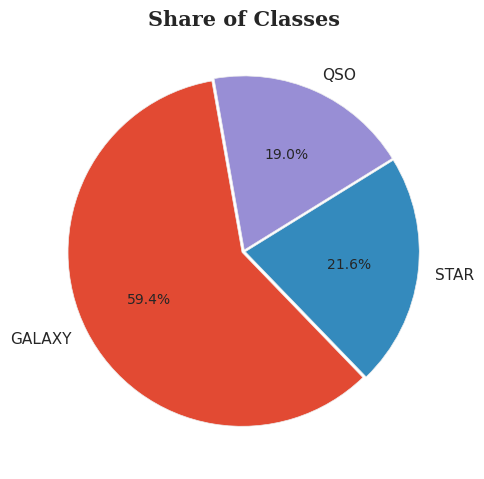

In [20]:
plt.figure(figsize=(5, 5))
df['class'].value_counts().plot.pie(explode=[0.01, 0.01, 0.01], autopct='%1.1f%%', shadow=False, startangle=100)
plt.title('Share of Classes', fontsize=15, fontfamily='serif', fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.show()

We are working with an imbalanced dataset. The majority class is galaxy, followed by star and quasar.

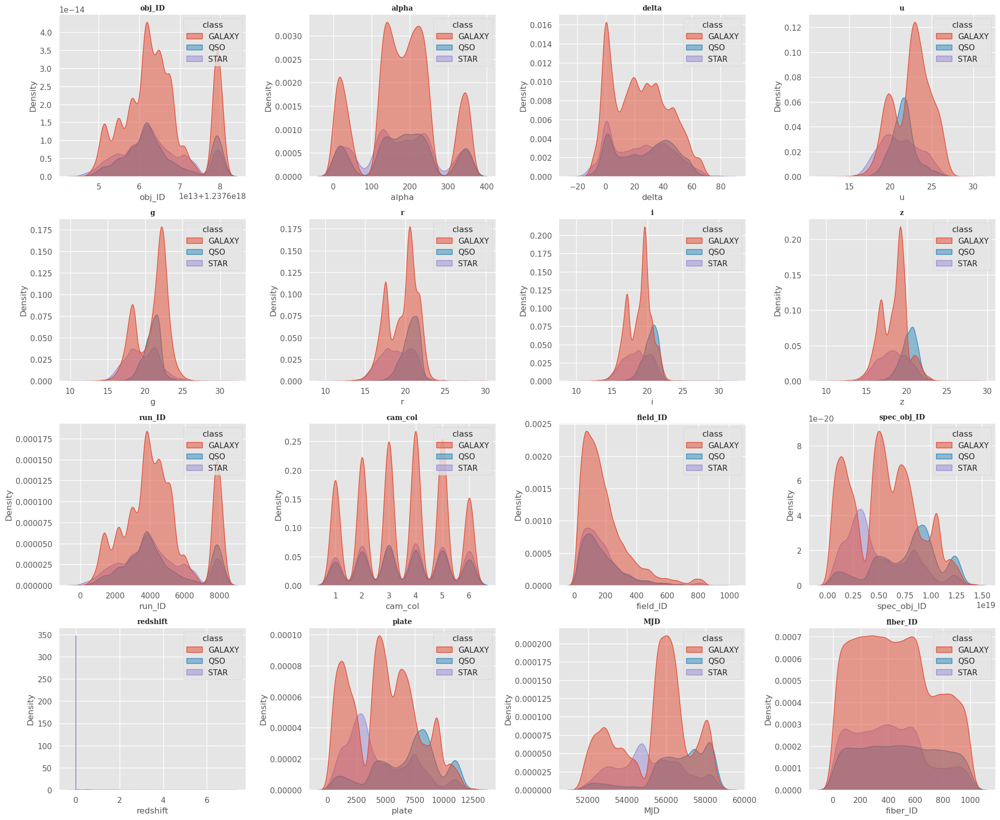

In [21]:
plt.figure(figsize=(20, 20))
for i, col in enumerate(df.drop(columns=['class']).columns,
                        start=1):
        plt.subplot(5, 4, i)
        sns.kdeplot(df, x = col,  fill=True, alpha=0.5, linewidth=1, hue='class')
        plt.title(col, fontsize=10, fontfamily='serif', fontweight='bold')
        plt.tight_layout()
plt.show()

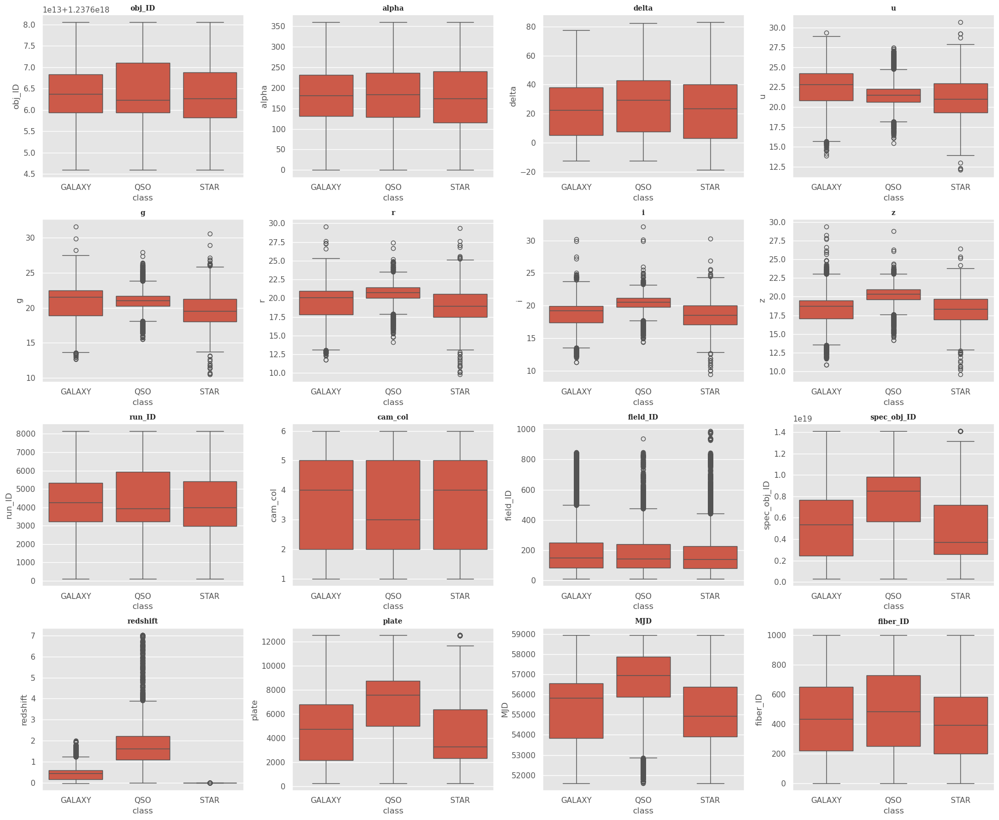

In [22]:
plt.figure(figsize=(20, 20))
for i, col in enumerate(df.drop(columns=['class']).columns,
                        start=1):
        plt.subplot(5, 4, i)
        sns.boxplot(data=df, x='class', y=col)
        plt.title(col, fontsize=10, fontfamily='serif', fontweight='bold')
        plt.tight_layout()
plt.show()

redshift??

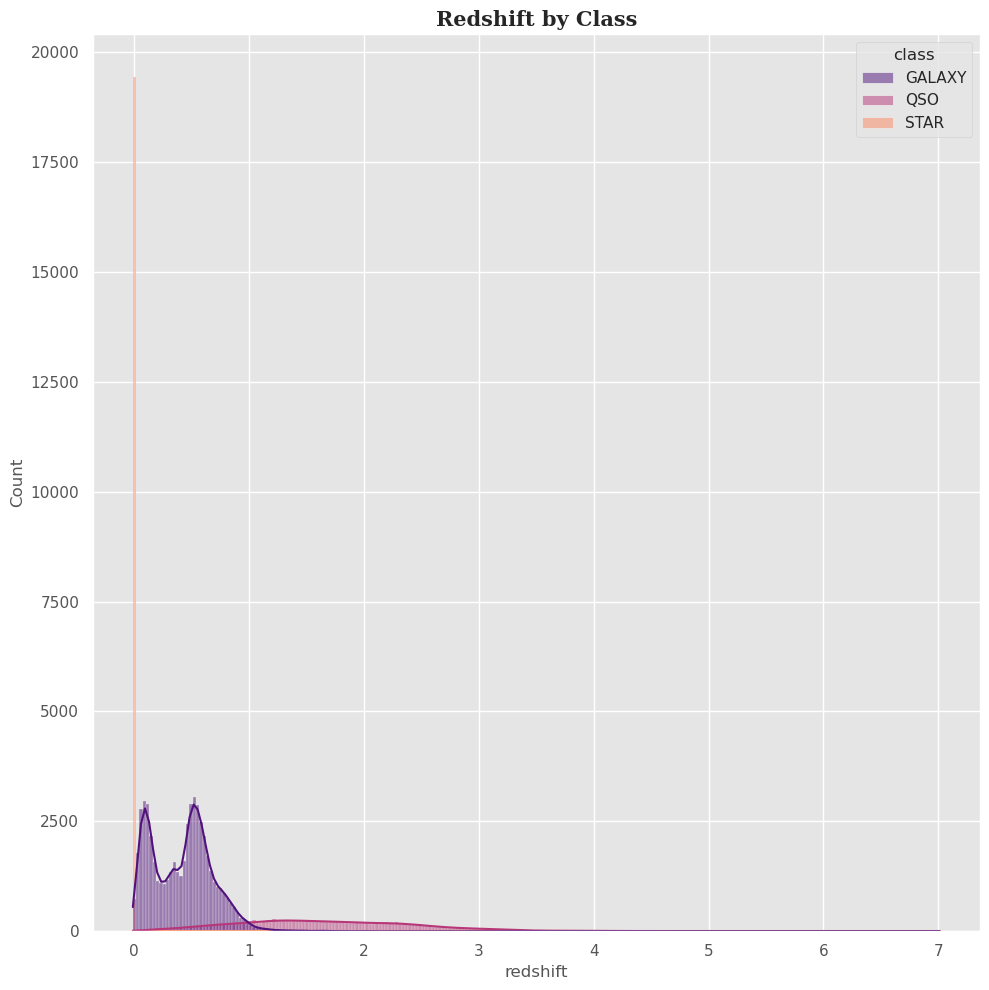

In [23]:
plt.figure(figsize=(10, 10))
sns.histplot(data=df, x='redshift', hue='class', kde=True, palette='magma')
plt.title('Redshift by Class', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.show()

Do all stars have redshift = 0??

In [24]:
df.loc[df['class'] == 'STAR']['redshift'].agg(['min', 'max'])

min   -0.004136
max    0.004153
Name: redshift, dtype: float64

In [25]:
df.groupby('class')['redshift'].agg(['min', 'max', 'mean', 'median'])

,min,max,mean,median
class,,,,
GALAXY,-0.009971,1.995524,0.421635,0.455896
QSO,0.000461,7.011245,1.720368,1.617716
STAR,-0.004136,0.004153,-0.000114,-0.000075


Redshift seems to be a strong predictor of class.

## Mulitvariate analysis

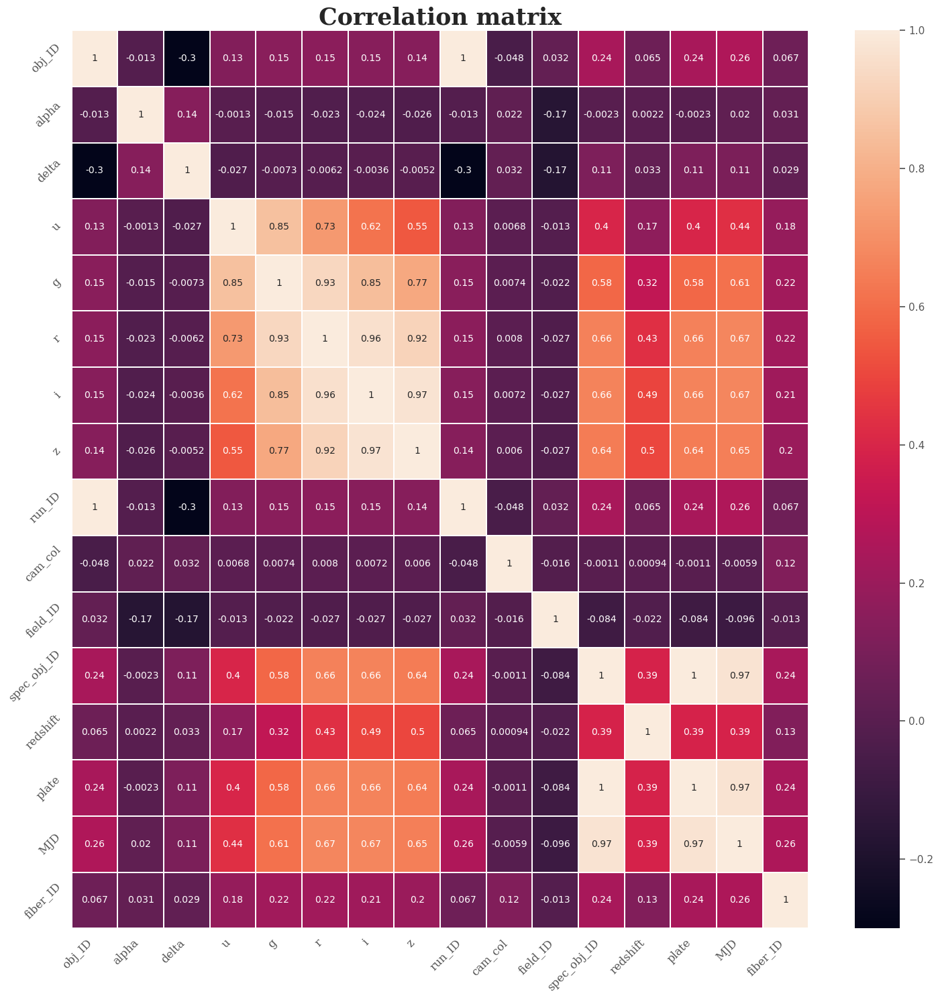

In [26]:
plt.figure(figsize=(15, 15))
sns.heatmap(df.corr(numeric_only=True), annot=True, linewidths=0.1, linecolor='white')
plt.title('Correlation matrix', fontsize=25, fontfamily='serif', fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=12, fontfamily='serif')
plt.yticks(rotation=45, ha='right', fontsize=12, fontfamily='serif')
plt.tight_layout()
plt.show()

Several features are correlated with each other. We will consider removing them during feature engineering.

### PCA

In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = df.drop(columns=['class'])
X = scaler.fit_transform(X)
pca = PCA()
pca.fit(X)

PCA()

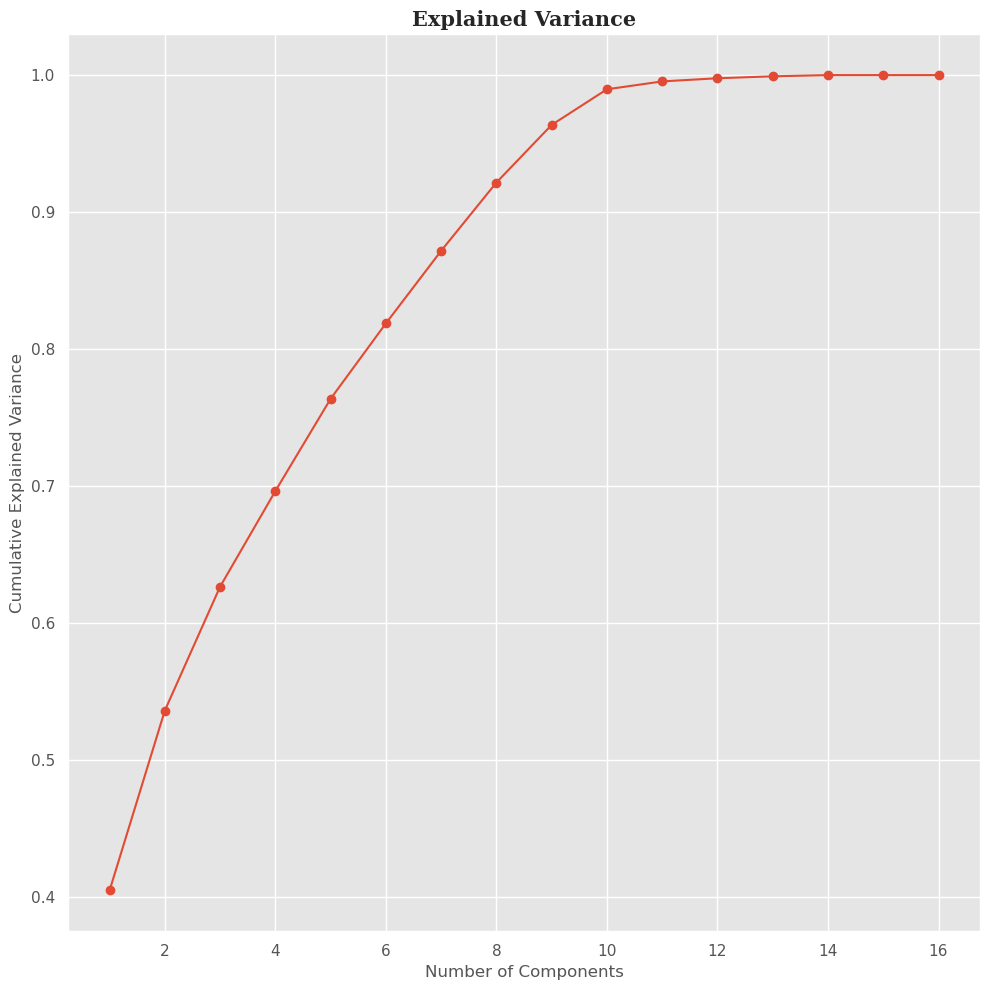

In [28]:
plt.figure(figsize=(10, 10))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_.cumsum(), marker='o')
plt.title('Explained Variance', fontsize=15, fontfamily='serif', fontweight='bold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.tight_layout()
plt.show()

### 3D PCA

In [29]:
import plotly.express as px

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)
df_pca = pd.DataFrame(X_pca, columns=['pca1', 'pca2', 'pca3'])
df_pca['class'] = df['class']

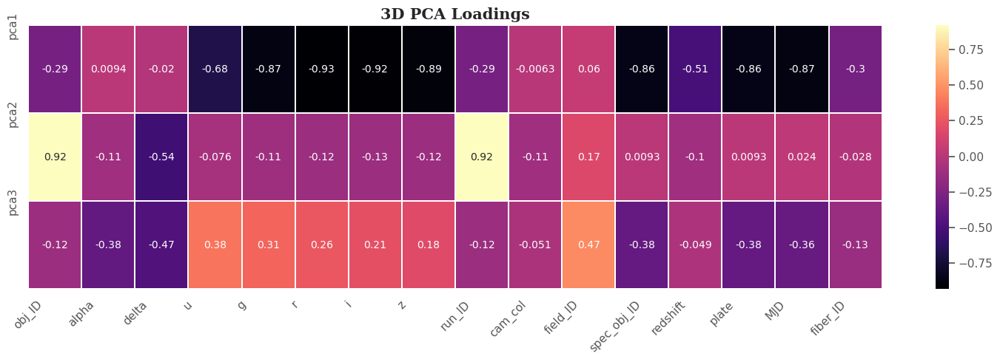

In [30]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

plt.figure(figsize=(15, 5))
sns.heatmap(loadings.T, cmap='magma', annot=True, linewidths=0.1, linecolor='white')
plt.xticks(range(len(df.columns) - 1), df.columns[:-1], rotation=45)
plt.yticks(range(3), ['pca1', 'pca2', 'pca3'])
plt.title('3D PCA Loadings', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.show()

In [32]:
fig = px.scatter_3d(df_pca, x='pca1', y='pca2', z='pca3', color='class', opacity=0.7)
fig.write_html('./3D_pca.html')
fig.show()

In [33]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
df_pca = pd.DataFrame(X_pca, columns=['pca1', 'pca2'])
df_pca['class'] = df['class']

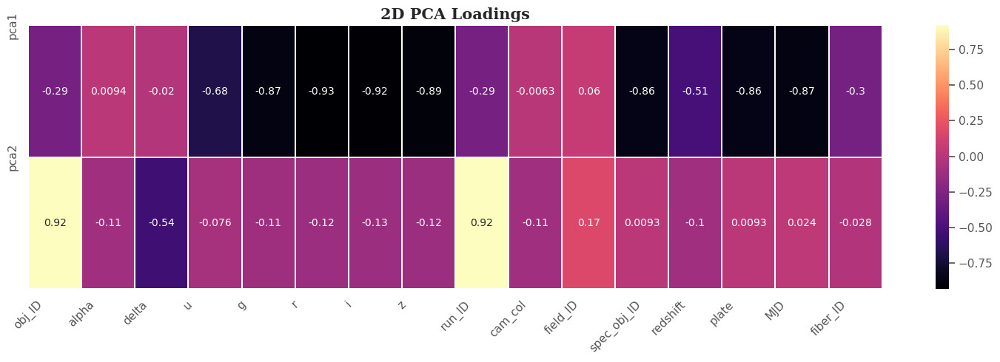

In [34]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
plt.figure(figsize=(15, 5))
sns.heatmap(loadings.T, cmap='magma', annot=True, linewidths=0.1, linecolor='white')
plt.xticks(range(len(df.columns) - 1), df.columns[:-1], rotation=45)
plt.yticks(range(2), ['pca1', 'pca2'])
plt.title('2D PCA Loadings', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.show()

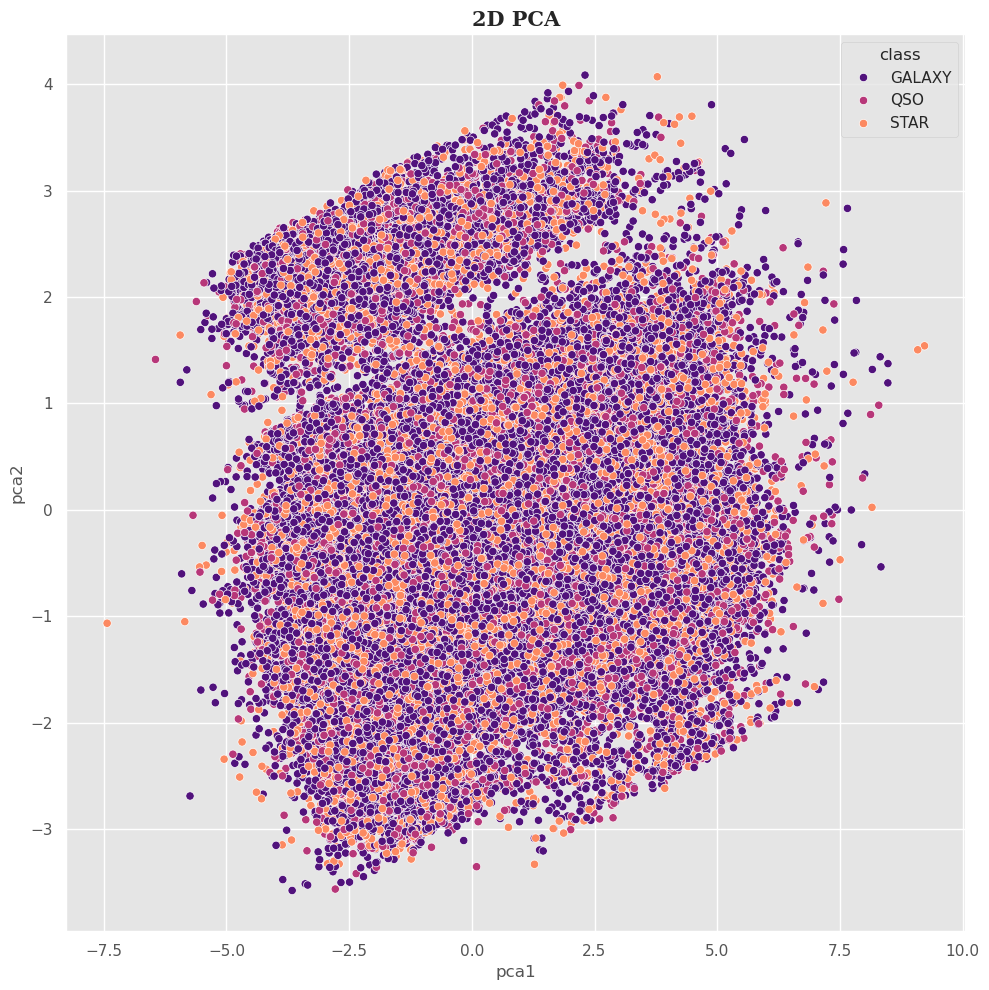

In [35]:
plt.figure(figsize=(10, 10))
sns.scatterplot(data=df_pca, x='pca1', y='pca2', hue='class', palette='magma')
plt.title('2D PCA', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.savefig('./2D_pca.png')
plt.show()

## t-SNE

### 2D t-SNE

In [36]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, init='pca', random_state=42)
X_tsne = tsne.fit_transform(X)
df_tsne = pd.DataFrame(X_tsne, columns=['tsne1', 'tsne2'])
df_tsne['class'] = df['class']

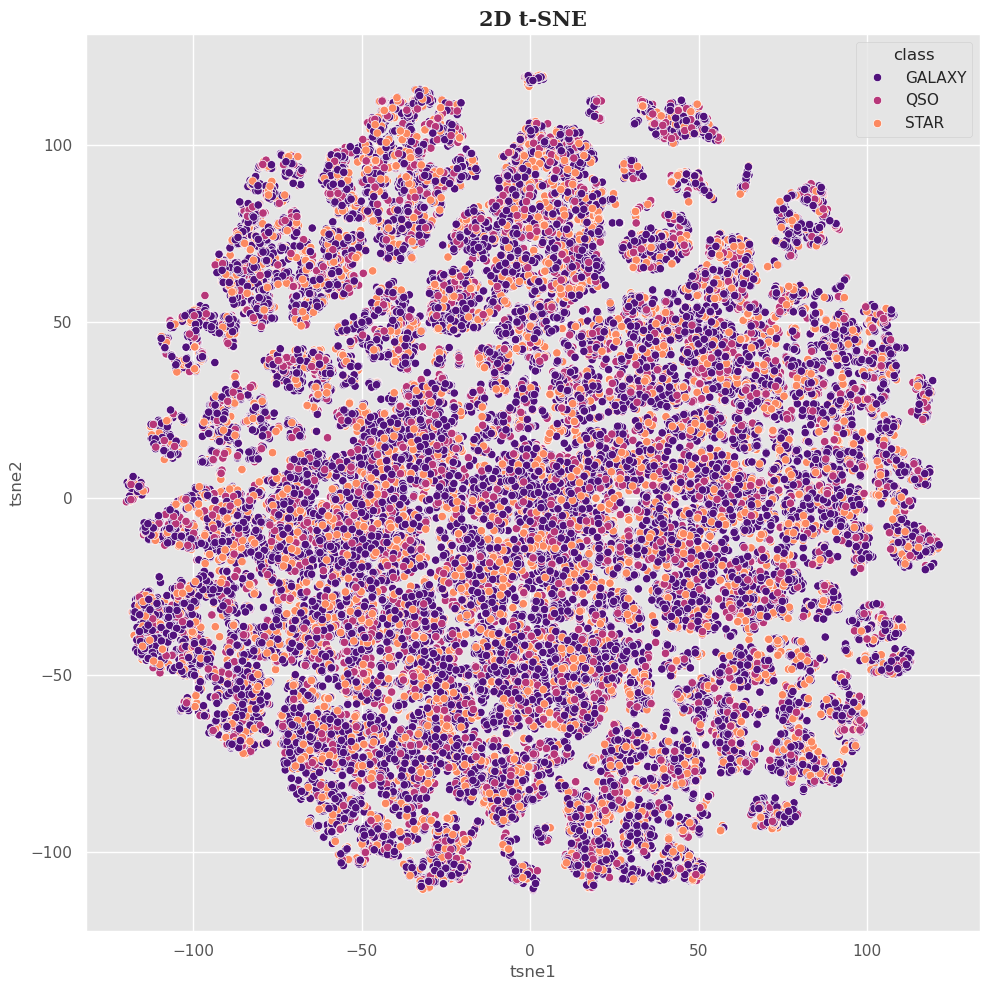

In [37]:
plt.figure(figsize=(10, 10))
sns.scatterplot(data=df_tsne, x='tsne1', y='tsne2', hue='class', palette='magma')
plt.title('2D t-SNE', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.savefig('./2D_tsne.png')
plt.show()

### 3D t-SNE

In [38]:
tsne = TSNE(n_components=3, init='pca', random_state=42)
X_tsne = tsne.fit_transform(X)
df_tsne = pd.DataFrame(X_tsne, columns=['tsne1', 'tsne2', 'tsne3'])
df_tsne['class'] = df['class']

In [39]:
fig = px.scatter_3d(df_tsne, x='tsne1', y='tsne2', z='tsne3', color='class', opacity=0.7)
fig.write_html('./3D_tsne.html')
fig.show()

## Save dataset split

In [40]:
df.to_csv('../dataset/star_classification_train.csv', index=False)
test.to_csv('../dataset/star_classification_test.csv', index=False)